## EDA

In [1]:
import pandas as pd

df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Stats Related To The Data

1. Basic Dataset Statistics
Metric	Value	Notes
Total Rows & Columns	541,909 rows × 8 columns	
Date Range	Dec 1, 2010 → Dec 9, 2011	~1 year and 1 week of transactional data
Unique Invoices	25,900	Includes regular orders, cancellations, adjustments
Unique Products	4,070 Stock Codes / 4,223 Descriptions	Slight mismatch between codes and descriptions
Unique Customers	4,372	Across 38 countries
Top Country	United Kingdom (495,478 rows)	~91.4% of all transactions; followed by Germany (9,495) and France (8,557)
Numerical Summary
Statistic	Quantity	UnitPrice (£)
Mean	9.55	£4.61
Median (50%)	3.00	£2.08
IQR (25% – 75%)	1.00 – 10.00	£1.25 – £4.13
Min	-80,995.00	-£11,062.06
Max	+80,995.00	£38,970.00
2. Immediate Data Quality Observations
1. High Proportion of Missing Customer IDs (24.93%)
135,080 rows (~25%) have a null CustomerID.
Impact: For customer-level analytics (e.g., RFM segmentation, customer lifetime value, retention/churn), you must decide whether to impute guest sessions or filter them out.
1,454 rows (0.27%) have missing Description values.
2. Duplicate Records
5,268 exact duplicate rows exist across all columns. These should typically be dropped prior to modeling or aggregation.
3. Cancellations & Negative Quantities
10,624 total rows have a negative Quantity:
9,288 rows have invoice numbers starting with 'C' (e.g., C581484), indicating standard customer cancellations/returns.
1,336 rows have negative quantities but no 'C' prefix. These are internal inventory write-offs, damaged stock, or lost goods (they have UnitPrice == 0.0 and missing descriptions).
4. Pricing Anomalies
2 Negative Prices: A563186 and A563187 have a price of -£11,062.06 with the description "Adjust bad debt". These are accounting adjustments, not retail transactions.
2,515 Zero-Price Items (UnitPrice == 0.0): Represent promotional giveaways, samples, system test entries, or damaged stock adjustments.
5. Extreme Outliers & Matching Cancellation Pairs
The minimum and maximum quantities are exact opposites: +80,995 and -80,995 (PAPER CRAFT , LITTLE BIRDIE, Customer 16446). An order of 80,995 units was placed on invoice 581483 and immediately cancelled on C581484.
Outliers like this heavily skew the mean quantity and total revenue if not handled.
6. Data Type Cleanup Needed
CustomerID is stored as a float64 due to NaN values (should be cast to string or pandas nullable integer Int64).
InvoiceNo is a mix of numeric codes and alphanumeric strings (due to prefixes 'C' and 'A').

## DATA CLEANING

In [2]:
# --- 1. CAPTURE 'BEFORE' METRICS ---
before_stats = {
    'Total Rows': len(df),
    'Duplicates': int(df.duplicated().sum()),
    'Missing CustomerID': int(df['CustomerID'].isnull().sum()),
    'Missing Description': int(df['Description'].isnull().sum()),
    'Cancelled Invoices': int(df['InvoiceNo'].astype(str).str.startswith('C').sum()),
    'Negative/Zero Quantity': int((df['Quantity'] <= 0).sum()),
    'Negative/Zero UnitPrice': int((df['UnitPrice'] <= 0).sum()),
    'Unique Invoices': int(df['InvoiceNo'].nunique()),
    'Unique Customers': int(df['CustomerID'].nunique())
}

# --- 2. CLEANING PIPELINE ---
# Step A: Remove duplicate rows
df_clean = df.drop_duplicates().copy()

# Step B: Remove rows with missing CustomerID or Description
df_clean = df_clean.dropna(subset=['CustomerID', 'Description'])

# Step C: Filter out cancelled/returned transactions (InvoiceNo starting with 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# Step D: Ensure positive Quantity and UnitPrice (removes write-offs, bad debt adjustments, zero-price items)
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# Step E: Convert CustomerID to integer type
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Step F: Create the 'Revenue' column (Quantity * UnitPrice)
df_clean['Revenue'] = (df_clean['Quantity'] * df_clean['UnitPrice']).round(2)

# --- 3. CAPTURE 'AFTER' METRICS ---
after_stats = {
    'Total Rows': len(df_clean),
    'Duplicates': int(df_clean.duplicated().sum()),
    'Missing CustomerID': int(df_clean['CustomerID'].isnull().sum()),
    'Missing Description': int(df_clean['Description'].isnull().sum()),
    'Cancelled Invoices': int(df_clean['InvoiceNo'].astype(str).str.startswith('C').sum()),
    'Negative/Zero Quantity': int((df_clean['Quantity'] <= 0).sum()),
    'Negative/Zero UnitPrice': int((df_clean['UnitPrice'] <= 0).sum()),
    'Unique Invoices': int(df_clean['InvoiceNo'].nunique()),
    'Unique Customers': int(df_clean['CustomerID'].nunique())
}

# --- 4. PRINT BEFORE AND AFTER COMPARISON ---
comparison_df = pd.DataFrame([before_stats, after_stats], index=['Before Cleaning', 'After Cleaning']).T
comparison_df['Change'] = comparison_df['After Cleaning'] - comparison_df['Before Cleaning']

print("=" * 65)
print("           DATASET CLEANING: BEFORE vs AFTER METRICS           ")
print("=" * 65)
print(comparison_df.to_string())
print("=" * 65)

print("\n--- Cleaned Dataset Numerical Summary ---")
print(df_clean[['Quantity', 'UnitPrice', 'Revenue']].describe().round(2))

print("\n--- Cleaned Dataset Overview ---")
print(f"Total Revenue: £{df_clean['Revenue'].sum():,.2f}")
print(f"Total Units Sold: {df_clean['Quantity'].sum():,}")
print(f"Total Active Customers: {df_clean['CustomerID'].nunique():,}")
print(f"Total Valid Orders: {df_clean['InvoiceNo'].nunique():,}")

           DATASET CLEANING: BEFORE vs AFTER METRICS           
                         Before Cleaning  After Cleaning  Change
Total Rows                        541909          392692 -149217
Duplicates                          5268               0   -5268
Missing CustomerID                135080               0 -135080
Missing Description                 1454               0   -1454
Cancelled Invoices                  9288               0   -9288
Negative/Zero Quantity             10624               0  -10624
Negative/Zero UnitPrice             2517               0   -2517
Unique Invoices                    25900           18532   -7368
Unique Customers                    4372            4338     -34

--- Cleaned Dataset Numerical Summary ---
        Quantity  UnitPrice    Revenue
count  392692.00  392692.00  392692.00
mean       13.12       3.13      22.63
std       180.49      22.24     311.10
min         1.00       0.00       0.00
25%         2.00       1.25       4.95
50%      

## BUSINESS ANALYSIS

## 1.Sales & Revenue Trends Over Time

--- Monthly Sales & Revenue Table ---


,YearMonth_Str,Revenue,Orders,Units_Sold,Active_Customers
0,2010-12,570422.73,1400,311048,885
1,2011-01,568101.31,987,348473,741
2,2011-02,446084.92,997,265027,758
3,2011-03,594081.76,1321,347582,974
4,2011-04,468374.33,1149,291366,856
5,2011-05,677355.15,1555,372864,1056
6,2011-06,660046.05,1393,363014,991
7,2011-07,598962.90,1331,367360,949
8,2011-08,644051.04,1280,397373,935
9,2011-09,950690.20,1755,543652,1266


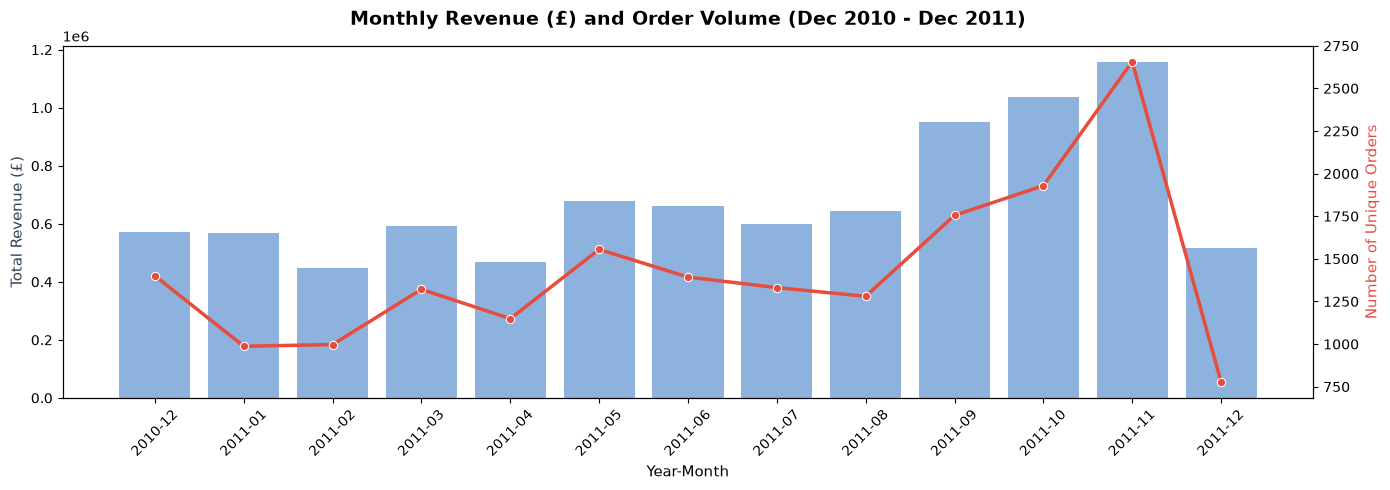

In [3]:
# Aggregate metrics by Year-Month
import matplotlib.pyplot as plt
import seaborn as sns
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly_trends = df_clean.groupby('YearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Units_Sold=('Quantity', 'sum'),
    Active_Customers=('CustomerID', 'nunique')
).reset_index()
monthly_trends['YearMonth_Str'] = monthly_trends['YearMonth'].astype(str)

print("--- Monthly Sales & Revenue Table ---")
display(monthly_trends[['YearMonth_Str', 'Revenue', 'Orders', 'Units_Sold', 'Active_Customers']])

# Visualizing Revenue & Order Volume Trends
fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

sns.barplot(data=monthly_trends, x='YearMonth_Str', y='Revenue', ax=ax1, color='#4A90E2', alpha=0.7)
sns.lineplot(data=monthly_trends, x='YearMonth_Str', y='Orders', ax=ax2, color='#E74C3C', marker='o', linewidth=2.5)

ax1.set_title('Monthly Revenue (£) and Order Volume (Dec 2010 - Dec 2011)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Year-Month', fontsize=11)
ax1.set_ylabel('Total Revenue (£)', fontsize=11, color='#2C3E50')
ax2.set_ylabel('Number of Unique Orders', fontsize=11, color='#E74C3C')
ax1.tick_params(axis='x', rotation=45)
plt.grid(False)
plt.tight_layout()
plt.show()

## 2.Geographic Distribution (Revenue, Sales & Order Value by Country)

--- Top 10 Countries by Revenue ---


,Country,Revenue,Orders,Units_Sold,Customers,AOV,Revenue_Share_%
0,United Kingdom,7285024.64,16646,4241305,3920,437.64,81.97
1,Netherlands,285446.34,94,200361,9,3036.66,3.21
2,EIRE,265262.46,260,140133,3,1020.24,2.98
3,Germany,228678.40,457,119154,94,500.39,2.57
4,France,208934.31,389,111428,87,537.11,2.35
5,Australia,138453.81,57,83891,9,2429.01,1.56
6,Spain,61558.56,90,27933,30,683.98,0.69
7,Switzerland,56443.95,51,30082,21,1106.74,0.64
8,Belgium,41196.34,98,23237,25,420.37,0.46
9,Sweden,38367.83,36,36078,8,1065.77,0.43


C:\Users\USER\AppData\Local\Temp\ipykernel_15484\552202453.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_intl, y='Country', x='Revenue', ax=axes[0], palette='Blues_r')
C:\Users\USER\AppData\Local\Temp\ipykernel_15484\552202453.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_intl, y='Country', x='AOV', ax=axes[1], palette='Oranges_r')


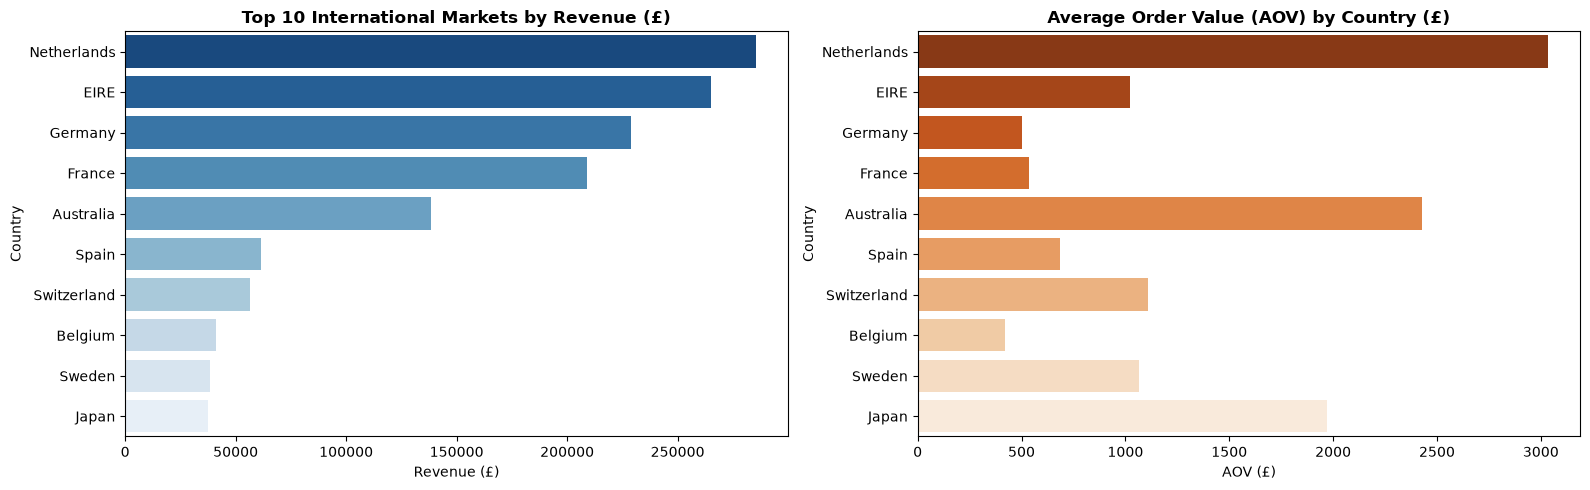

In [4]:
# Aggregate geographic performance metrics
import matplotlib.pyplot as plt
import seaborn as sns
geo_summary = df_clean.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Units_Sold=('Quantity', 'sum'),
    Customers=('CustomerID', 'nunique')
).reset_index()

geo_summary['AOV'] = (geo_summary['Revenue'] / geo_summary['Orders']).round(2)
geo_summary['Revenue_Share_%'] = ((geo_summary['Revenue'] / df_clean['Revenue'].sum()) * 100).round(2)
geo_summary = geo_summary.sort_values(by='Revenue', ascending=False).reset_index(drop=True)

print("--- Top 10 Countries by Revenue ---")
display(geo_summary.head(10))

# Visualizing Top 10 International Markets (excluding UK to highlight regional comparison)
top_intl = geo_summary[geo_summary['Country'] != 'United Kingdom'].head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=top_intl, y='Country', x='Revenue', ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 International Markets by Revenue (£)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue (£)')

sns.barplot(data=top_intl, y='Country', x='AOV', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Average Order Value (AOV) by Country (£)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('AOV (£)')

plt.tight_layout()
plt.show()

## 3.Top Performing Products

--- Top 10 Products by Revenue ---


,StockCode,Description,Total_Revenue,Units_Sold,Total_Orders
2529,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
1245,22423,REGENCY CAKESTAND 3 TIER,142264.75,12374,1703
3576,85123A,WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706,1971
3569,85099B,JUMBO BAG RED RETROSPOT,85040.54,46078,1600
2027,23166,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916,195
3896,POST,POSTAGE,77803.96,3120,1099
2607,47566,PARTY BUNTING,68785.23,15279,1379
2810,84879,ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263,1375
3894,M,Manual,53419.93,6933,253
1933,23084,RABBIT NIGHT LIGHT,51251.24,27153,801



--- Top 10 Products by Units Sold ---


,StockCode,Description,Total_Revenue,Units_Sold,Total_Orders
2529,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2027,23166,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916,195
2705,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13558.41,54319,472
3569,85099B,JUMBO BAG RED RETROSPOT,85040.54,46078,1600
3576,85123A,WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706,1971
2810,84879,ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263,1375
359,21212,PACK OF 72 RETROSPOT CAKE CASES,16381.88,33670,1029
1035,22197,POPCORN HOLDER,23417.51,30919,632
1933,23084,RABBIT NIGHT LIGHT,51251.24,27153,801
1310,22492,MINI PAINT SET VINTAGE,16039.24,26076,325


C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3840759293.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products_rev, y='Description', x='Total_Revenue', ax=axes[0], palette='viridis')
C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3840759293.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products_qty, y='Description', x='Units_Sold', ax=axes[1], palette='magma')


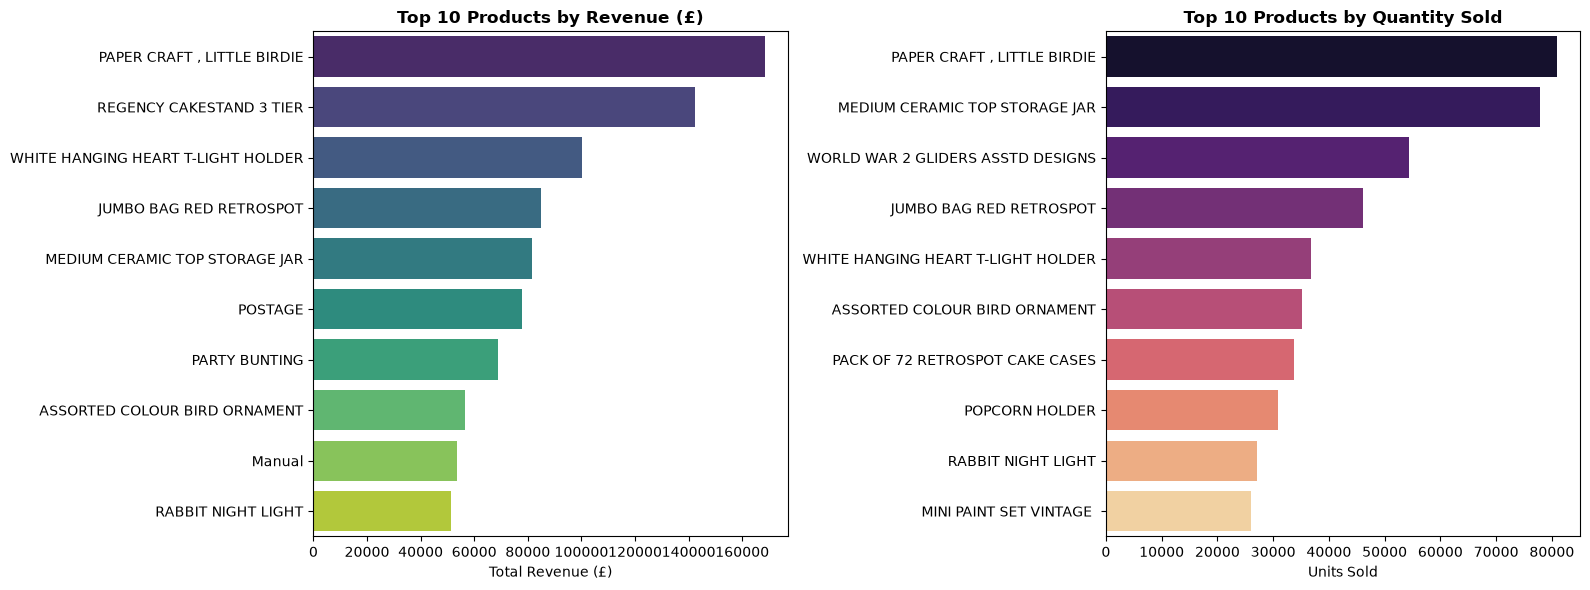

In [5]:
# Top 10 Products by Revenue
import matplotlib.pyplot as plt
import seaborn as sns
top_products_rev = df_clean.groupby(['StockCode', 'Description']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique')
).reset_index().sort_values(by='Total_Revenue', ascending=False).head(10)

# Top 10 Products by Quantity Sold
top_products_qty = df_clean.groupby(['StockCode', 'Description']).agg(
    Total_Revenue=('Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique')
).reset_index().sort_values(by='Units_Sold', ascending=False).head(10)

print("--- Top 10 Products by Revenue ---")
display(top_products_rev)

print("\n--- Top 10 Products by Units Sold ---")
display(top_products_qty)

# Visualizing Top Products
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_products_rev, y='Description', x='Total_Revenue', ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 Products by Revenue (£)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total Revenue (£)')
axes[0].set_ylabel('')

sns.barplot(data=top_products_qty, y='Description', x='Units_Sold', ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Products by Quantity Sold', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Units Sold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 4. Average Order Value (AOV) Analysis

--- Order Value Distribution Metrics ---
       Order_Revenue  Items_Count  Unique_SKUs
count       18532.00     18532.00     18532.00
mean          479.56       278.01        20.93
std          1678.08       972.39        23.82
min             0.38         1.00         1.00
25%           157.34        74.00         6.00
50%           302.58       154.00        15.00
75%           469.57       290.00        27.00
max        168469.60     80995.00       541.00

--- Monthly Average & Median Order Value ---


,YearMonth,Mean_AOV,Median_AOV,Order_Count,YearMonth_Str
0,2010-12,407.444807,266.050,1400,2010-12
1,2011-01,575.583901,303.040,987,2011-01
2,2011-02,447.427202,299.720,997,2011-02
3,2011-03,449.721241,294.170,1321,2011-03
4,2011-04,407.636493,301.480,1149,2011-04
5,2011-05,435.598167,303.610,1555,2011-05
6,2011-06,473.830617,289.240,1393,2011-06
7,2011-07,450.009692,302.920,1331,2011-07
8,2011-08,503.164875,304.795,1280,2011-08
9,2011-09,541.703818,322.940,1755,2011-09


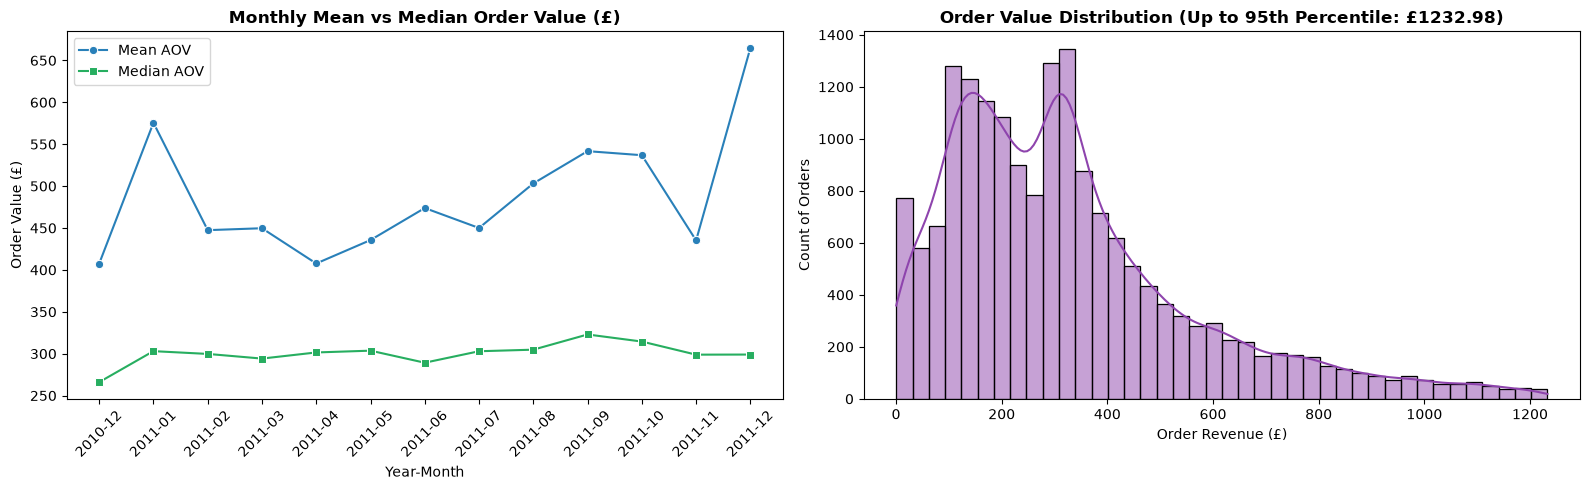

In [6]:
# Order-level aggregation
import matplotlib.pyplot as plt
import seaborn as sns
order_summary = df_clean.groupby('InvoiceNo').agg(
    Order_Revenue=('Revenue', 'sum'),
    Items_Count=('Quantity', 'sum'),
    Unique_SKUs=('StockCode', 'nunique'),
    InvoiceDate=('InvoiceDate', 'first'),
    CustomerID=('CustomerID', 'first'),
    Country=('Country', 'first')
).reset_index()

order_summary['YearMonth'] = order_summary['InvoiceDate'].dt.to_period('M')

print("--- Order Value Distribution Metrics ---")
print(order_summary[['Order_Revenue', 'Items_Count', 'Unique_SKUs']].describe().round(2))

# Monthly AOV Trend
monthly_aov = order_summary.groupby('YearMonth').agg(
    Mean_AOV=('Order_Revenue', 'mean'),
    Median_AOV=('Order_Revenue', 'median'),
    Order_Count=('Order_Revenue', 'count')
).reset_index()
monthly_aov['YearMonth_Str'] = monthly_aov['YearMonth'].astype(str)

print("\n--- Monthly Average & Median Order Value ---")
display(monthly_aov)

# Visualizing Order Value Trend & Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Trend over time
sns.lineplot(data=monthly_aov, x='YearMonth_Str', y='Mean_AOV', ax=axes[0], marker='o', label='Mean AOV', color='#2980B9')
sns.lineplot(data=monthly_aov, x='YearMonth_Str', y='Median_AOV', ax=axes[0], marker='s', label='Median AOV', color='#27AE60')
axes[0].set_title('Monthly Mean vs Median Order Value (£)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Year-Month')
axes[0].set_ylabel('Order Value (£)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Distribution (clipped at 95th percentile to clearly show the core distribution)
q95 = order_summary['Order_Revenue'].quantile(0.95)
sns.histplot(order_summary[order_summary['Order_Revenue'] <= q95]['Order_Revenue'], bins=40, kde=True, ax=axes[1], color='#8E44AD')
axes[1].set_title(f'Order Value Distribution (Up to 95th Percentile: £{q95:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Order Revenue (£)')
axes[1].set_ylabel('Count of Orders')

plt.tight_layout()
plt.show()

--- Top Product Categories Contributing to Revenue ---


,Category,Revenue,Units_Sold,Unique_Orders,Active_SKUs,Revenue_Share_%
0,Home Decor & Lighting,"£2,291,122.53","1,142,694","14,685",844,25.78%
1,Kitchenware & Dining,"£2,019,361.57","1,076,560","14,254",652,22.72%
2,Gifts & Miscellaneous,"£1,420,672.18","826,196","14,196",911,15.99%
3,Bags & Luggage,"£954,153.46","626,273","8,993",218,10.74%
4,Storage & Organization,"£867,267.85","345,347","10,567",230,9.76%
5,Stationery & Craft,"£691,321.51","666,370","9,305",348,7.78%
6,Seasonal & Holiday,"£307,313.49","244,385","5,030",176,3.46%
7,"Toys, Games & Novelty","£265,930.16","172,916","5,575",87,2.99%
8,Jewelry & Accessories,"£70,066.14","51,261","2,624",225,0.79%


C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3017400366.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, y='Category', x='Revenue', ax=axes[0], palette='Blues_r')


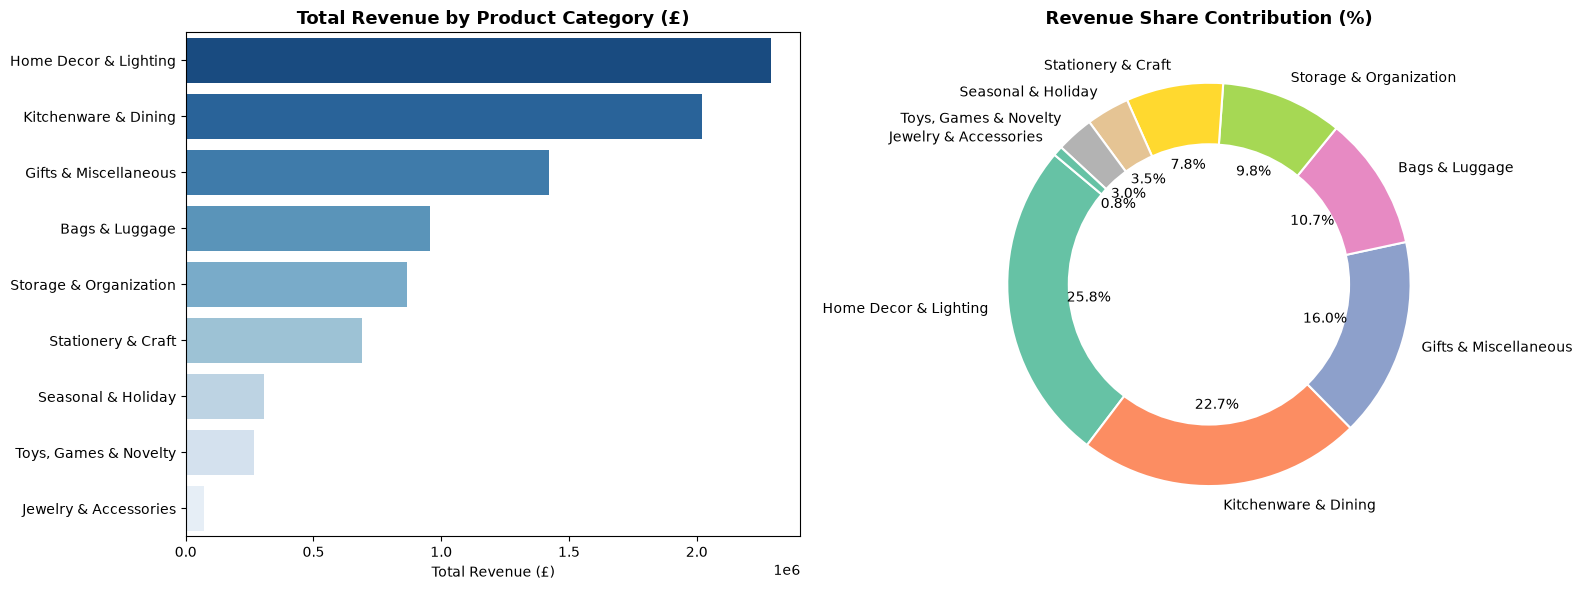

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df_clean exists; if not, create it from df
if 'df_clean' not in locals():
    if 'df' not in locals():
        print("Loading dataset from file...")
        df = pd.read_excel('Online Retail.xlsx')
    
    print("Preparing df_clean...")
    df_clean = df.drop_duplicates().copy()
    df_clean = df_clean.dropna(subset=['CustomerID', 'Description'])
    df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
    df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
    df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
    df_clean['Revenue'] = (df_clean['Quantity'] * df_clean['UnitPrice']).round(2)

# ==========================================
# 1. CATEGORIZATION LOGIC
# ==========================================
def assign_category(desc):
    if not isinstance(desc, str):
        return 'Gifts & Miscellaneous'
    
    d = desc.upper()
    
    if any(k in d for k in ['BAG', 'LUNCH BAG', 'TOTE', 'SHOPPER', 'BACKPACK', 'PURSE', 'WALLET']):
        return 'Bags & Luggage'
    elif any(k in d for k in ['CAKE', 'MUG', 'CUP', 'TEA', 'BOTTLE', 'BOWL', 'PLATE', 'DISH', 
                             'CUTLERY', 'JAR', 'PANTRY', 'GLASS', 'KITCHEN', 'BAKING', 'FORK', 'SPOON']):
        return 'Kitchenware & Dining'
    elif any(k in d for k in ['HEART', 'LIGHT', 'HOLDER', 'SIGN', 'CANDLE', 'LANTERN', 'CLOCK', 
                             'MIRROR', 'CUSHION', 'PILLOW', 'FRAME', 'VASE', 'WALL ART', 'DOORMAT']):
        return 'Home Decor & Lighting'
    elif any(k in d for k in ['CHRISTMAS', 'XMAS', 'TREE', 'SNOWFLAKE', 'EASTER', 'HALLOWEEN', 
                             'ADVENT', 'CALENDAR', 'SANTA', 'REINDEER']):
        return 'Seasonal & Holiday'
    elif any(k in d for k in ['PAPER', 'CARD', 'CRAFT', 'NOTEBOOK', 'PENCIL', 'PEN', 'WRAP', 
                             'STICKER', 'RIBBON', 'ALBUM', 'STATIONERY', 'TAPE']):
        return 'Stationery & Craft'
    elif any(k in d for k in ['TOY', 'GAME', 'SPACEBOY', 'DOLL', 'PUZZLE', 'PLAYING CARDS', 
                             'CHILDRENS', 'MINI', 'CIRCUS', 'KIDS']):
        return 'Toys, Games & Novelty'
    elif any(k in d for k in ['BOX', 'TIN', 'BASKET', 'DRAWER', 'CASE', 'STORAGE', 'CABINET', 'HOOK']):
        return 'Storage & Organization'
    elif any(k in d for k in ['NECKLACE', 'BRACELET', 'EARRINGS', 'RING', 'JEWELLERY', 'SCARF', 'BADGE']):
        return 'Jewelry & Accessories'
    else:
        return 'Gifts & Miscellaneous'

# Apply categorization
df_clean['Category'] = df_clean['Description'].apply(assign_category)

# ==========================================
# 2. AGGREGATE REVENUE & PERFORMANCE METRICS
# ==========================================
category_summary = df_clean.groupby('Category').agg(
    Revenue=('Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Unique_Orders=('InvoiceNo', 'nunique'),
    Active_SKUs=('StockCode', 'nunique')
).reset_index()

category_summary['Revenue_Share_%'] = ((category_summary['Revenue'] / df_clean['Revenue'].sum()) * 100).round(2)
category_summary = category_summary.sort_values(by='Revenue', ascending=False).reset_index(drop=True)

print("--- Top Product Categories Contributing to Revenue ---")
# Format the numbers directly on a copy for clean display:
formatted_summary = category_summary.copy()
formatted_summary['Revenue'] = formatted_summary['Revenue'].apply(lambda x: f"£{x:,.2f}")
formatted_summary['Units_Sold'] = formatted_summary['Units_Sold'].apply(lambda x: f"{x:,}")
formatted_summary['Unique_Orders'] = formatted_summary['Unique_Orders'].apply(lambda x: f"{x:,}")
formatted_summary['Active_SKUs'] = formatted_summary['Active_SKUs'].apply(lambda x: f"{x:,}")
formatted_summary['Revenue_Share_%'] = formatted_summary['Revenue_Share_%'].apply(lambda x: f"{x:.2f}%")

display(formatted_summary)

 

# ==========================================
# 3. VISUALIZATION
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar Chart
sns.barplot(data=category_summary, y='Category', x='Revenue', ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Revenue by Product Category (£)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Revenue (£)')
axes[0].set_ylabel('')

# Donut Chart
axes[1].pie(
    category_summary['Revenue'],
    labels=category_summary['Category'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2', len(category_summary)),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title('Revenue Share Contribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

Data ready! Computing category economics...

--- Product Category Economics (AOV, Bulk & Catalog Efficiency) ---


,Category,Category_AOV,Mean_Units_Per_Line,Units_Per_Order,Realized_ASP,Revenue_Per_SKU,Unique_SKUs
0,Home Decor & Lighting,£156.02,12.5 pcs,77.8 pcs,£2.01,"£2,714.60",844
1,Kitchenware & Dining,£141.67,13.0 pcs,75.5 pcs,£1.88,"£3,097.18",652
2,Bags & Luggage,£106.10,14.4 pcs,69.6 pcs,£1.52,"£4,376.85",218
3,Gifts & Miscellaneous,£100.08,11.7 pcs,58.2 pcs,£1.72,"£1,559.46",911
4,Storage & Organization,£82.07,10.6 pcs,32.7 pcs,£2.51,"£3,770.73",230
5,Stationery & Craft,£74.30,17.8 pcs,71.6 pcs,£1.04,"£1,986.56",348
6,Seasonal & Holiday,£61.10,13.9 pcs,48.6 pcs,£1.26,"£1,746.10",176
7,"Toys, Games & Novelty",£47.70,13.9 pcs,31.0 pcs,£1.54,"£3,056.67",87
8,Jewelry & Accessories,£26.70,12.0 pcs,19.5 pcs,£1.37,£311.41,225


C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3149846088.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_econ, y='Category', x='Category_AOV', ax=axes[0], palette='Blues_r')
C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3149846088.py:107: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_econ.sort_values(by='Mean_Units_Per_Line', ascending=False),
C:\Users\USER\AppData\Local\Temp\ipykernel_15484\3149846088.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_econ.sort_values(by='Revenue_Per_SKU', ascending

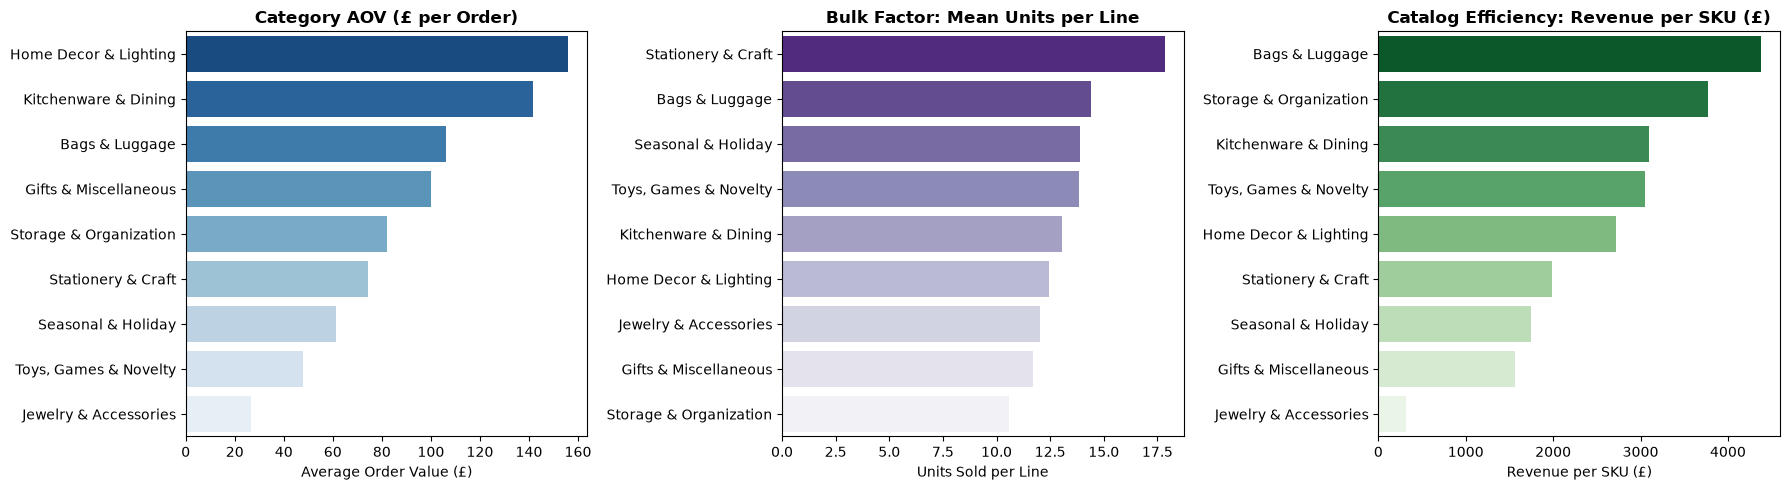

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 0. ENSURE DF_CLEAN & CATEGORY ARE LOADED
# ==========================================
if 'df_clean' not in locals():
    if 'df' not in locals():
        print("Loading dataset from Excel file (this takes a few seconds)...")
        df = pd.read_excel('Online Retail.xlsx')
    
    print("Preparing cleaned data...")
    df_clean = df.drop_duplicates().copy()
    df_clean = df_clean.dropna(subset=['CustomerID', 'Description'])
    df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
    df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
    df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
    df_clean['Revenue'] = (df_clean['Quantity'] * df_clean['UnitPrice']).round(2)

if 'Category' not in df_clean.columns:
    print("Assigning product categories...")
    def assign_category(desc):
        if not isinstance(desc, str):
            return 'Gifts & Miscellaneous'
        d = desc.upper()
        if any(k in d for k in ['BAG', 'LUNCH BAG', 'TOTE', 'SHOPPER', 'BACKPACK', 'PURSE', 'WALLET']):
            return 'Bags & Luggage'
        elif any(k in d for k in ['CAKE', 'MUG', 'CUP', 'TEA', 'BOTTLE', 'BOWL', 'PLATE', 'DISH', 
                                 'CUTLERY', 'JAR', 'PANTRY', 'GLASS', 'KITCHEN', 'BAKING', 'FORK', 'SPOON']):
            return 'Kitchenware & Dining'
        elif any(k in d for k in ['HEART', 'LIGHT', 'HOLDER', 'SIGN', 'CANDLE', 'LANTERN', 'CLOCK', 
                                 'MIRROR', 'CUSHION', 'PILLOW', 'FRAME', 'VASE', 'WALL ART', 'DOORMAT']):
            return 'Home Decor & Lighting'
        elif any(k in d for k in ['CHRISTMAS', 'XMAS', 'TREE', 'SNOWFLAKE', 'EASTER', 'HALLOWEEN', 
                                 'ADVENT', 'CALENDAR', 'SANTA', 'REINDEER']):
            return 'Seasonal & Holiday'
        elif any(k in d for k in ['PAPER', 'CARD', 'CRAFT', 'NOTEBOOK', 'PENCIL', 'PEN', 'WRAP', 
                                 'STICKER', 'RIBBON', 'ALBUM', 'STATIONERY', 'TAPE']):
            return 'Stationery & Craft'
        elif any(k in d for k in ['TOY', 'GAME', 'SPACEBOY', 'DOLL', 'PUZZLE', 'PLAYING CARDS', 
                                 'CHILDRENS', 'MINI', 'CIRCUS', 'KIDS']):
            return 'Toys, Games & Novelty'
        elif any(k in d for k in ['BOX', 'TIN', 'BASKET', 'DRAWER', 'CASE', 'STORAGE', 'CABINET', 'HOOK']):
            return 'Storage & Organization'
        elif any(k in d for k in ['NECKLACE', 'BRACELET', 'EARRINGS', 'RING', 'JEWELLERY', 'SCARF', 'BADGE']):
            return 'Jewelry & Accessories'
        else:
            return 'Gifts & Miscellaneous'
    
    df_clean['Category'] = df_clean['Description'].apply(assign_category)

print("Data ready! Computing category economics...")

# ==========================================
# 1. COMPUTE CATEGORY-LEVEL ORDER ECONOMICS
# ==========================================
cat_econ = df_clean.groupby('Category').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Units=('Quantity', 'sum'),
    Unique_Orders=('InvoiceNo', 'nunique'),
    Line_Items=('InvoiceNo', 'count'),
    Unique_SKUs=('StockCode', 'nunique'),
    Avg_Unit_Price=('UnitPrice', 'mean'),
    Median_Units_Per_Line=('Quantity', 'median'),
    Mean_Units_Per_Line=('Quantity', 'mean')
).reset_index()

# 2. STRATEGIC RATIOS
cat_econ['Category_AOV'] = (cat_econ['Total_Revenue'] / cat_econ['Unique_Orders']).round(2)
cat_econ['Units_Per_Order'] = (cat_econ['Total_Units'] / cat_econ['Unique_Orders']).round(1)
cat_econ['Realized_ASP'] = (cat_econ['Total_Revenue'] / cat_econ['Total_Units']).round(2)
cat_econ['Revenue_Per_SKU'] = (cat_econ['Total_Revenue'] / cat_econ['Unique_SKUs']).round(2)

cat_econ = cat_econ.sort_values(by='Category_AOV', ascending=False).reset_index(drop=True)

# ==========================================
# 3. DISPLAY SUMMARY TABLE
# ==========================================
display_table = cat_econ[[
    'Category', 'Category_AOV', 'Mean_Units_Per_Line', 'Units_Per_Order', 
    'Realized_ASP', 'Revenue_Per_SKU', 'Unique_SKUs'
]].copy()

display_table['Category_AOV'] = display_table['Category_AOV'].apply(lambda x: f"£{x:,.2f}")
display_table['Mean_Units_Per_Line'] = display_table['Mean_Units_Per_Line'].apply(lambda x: f"{x:,.1f} pcs")
display_table['Units_Per_Order'] = display_table['Units_Per_Order'].apply(lambda x: f"{x:,.1f} pcs")
display_table['Realized_ASP'] = display_table['Realized_ASP'].apply(lambda x: f"£{x:,.2f}")
display_table['Revenue_Per_SKU'] = display_table['Revenue_Per_SKU'].apply(lambda x: f"£{x:,.2f}")

print("\n--- Product Category Economics (AOV, Bulk & Catalog Efficiency) ---")
display(display_table)

# ==========================================
# 4. VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: AOV
sns.barplot(data=cat_econ, y='Category', x='Category_AOV', ax=axes[0], palette='Blues_r')
axes[0].set_title('Category AOV (£ per Order)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Order Value (£)')
axes[0].set_ylabel('')

# Plot 2: Bulk Units
sns.barplot(data=cat_econ.sort_values(by='Mean_Units_Per_Line', ascending=False), 
            y='Category', x='Mean_Units_Per_Line', ax=axes[1], palette='Purples_r')
axes[1].set_title('Bulk Factor: Mean Units per Line', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Units Sold per Line')
axes[1].set_ylabel('')

# Plot 3: SKU Productivity
sns.barplot(data=cat_econ.sort_values(by='Revenue_Per_SKU', ascending=False), 
            y='Category', x='Revenue_Per_SKU', ax=axes[2], palette='Greens_r')
axes[2].set_title('Catalog Efficiency: Revenue per SKU (£)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Revenue per SKU (£)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()